# Phần 5: Tính Toán Dự Báo Quý 1/2026 & Báo Cáo Tổng Quan Dự Án (Forecast & Executive Report)
## Tổng Hợp Dự Báo 3.869 Dòng, Phân Tích Kinh Doanh Chuyên Sâu & Khuyến Nghị Vận Hành Cho Ban Giám Đốc

---

### 1. Phân Tích Chuyên Sâu Cách Làm:
Phần 5 là đích đến cuối cùng của dự án, tổng hợp toàn bộ các kết quả tính toán từ Phần 1 đến Phần 4:
1. **Tính toán dự báo trên 100% dữ liệu test thực tế (`test.csv`):** Dự báo doanh thu cho từng ngày của từng quán trong Quý 1/2026 với 380 ngày khuyến mãi chính xác.
2. **Báo cáo thống kê phân phối doanh thu:** Min, Max, Median, Mean, Std, Tứ phân vị.
3. **Phân tích kinh doanh đa chiều:**
   - Doanh thu theo loại hình quán (Mall, Office, Residential, Street, University).
   - Doanh thu theo thành phố (Hà Nội, TP.HCM, Đà Nẵng).
   - Mức độ bứt phá doanh thu trong các ngày chạy khuyến mãi (+31%).
4. **Phân tích chuỗi thời gian Quý 1/2026:** Nhận diện các điểm uốn chiến lược (Đợt Siêu Sale 05-08/01, Lễ Tình Nhân Valentine 14/02, Tết Bính Ngọ 17/02, Quốc tế Phụ Nữ 08/03).
5. **Khuyến nghị vận hành & quản trị:** Chuẩn bị nguyên vật liệu, ca trực nhân sự và chiến lược khuyến mãi.
6. **Kiểm tra toàn vẹn file nộp bài chuẩn Kaggle (`submission.csv`).**

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
    if p not in sys.path and os.path.exists(os.path.join(p, "src")):
        sys.path.insert(0, p)

from src.config import CAFE_MODEL_V3_PATH, SUBMISSION_V3_PATH, SUBMISSION_PATH, SAMPLE_SUB_PATH
from src.cleaning import clean_stores, clean_test
from src.cafe_model_v3 import CafeRevenueModelV3

# 1. Nạp mô hình tối ưu đã lưu
model = CafeRevenueModelV3.load(CAFE_MODEL_V3_PATH)
stores_c = clean_stores(pd.read_csv(os.path.join(DATA_DIR, "stores.csv")))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)

test_c, test_stats = clean_test(test_raw, stores_c)
test_c["predicted_revenue"] = model.predict(test_c)

# Ghép thông tin cửa hàng để phân tích
test_merged = test_c.merge(stores_c, on="store_id", how="left")

print("TỔNG HỢP KẾT QUẢ DỰ BÁO DOANH THU QUÝ 1/2026:")
display(test_merged["predicted_revenue"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame())

TỔNG HỢP KẾT QUẢ DỰ BÁO DOANH THU QUÝ 1/2026:


,predicted_revenue
count,3869.000000
mean,20.271939
std,8.890935
min,1.922027
5%,7.103249
25%,14.007475
50%,19.810551
75%,26.012590
95%,35.586077
max,69.903999


### 2. Hệ Thống Đồ Thị Phân Tích Kinh Doanh Toàn Chuỗi Quý 1/2026

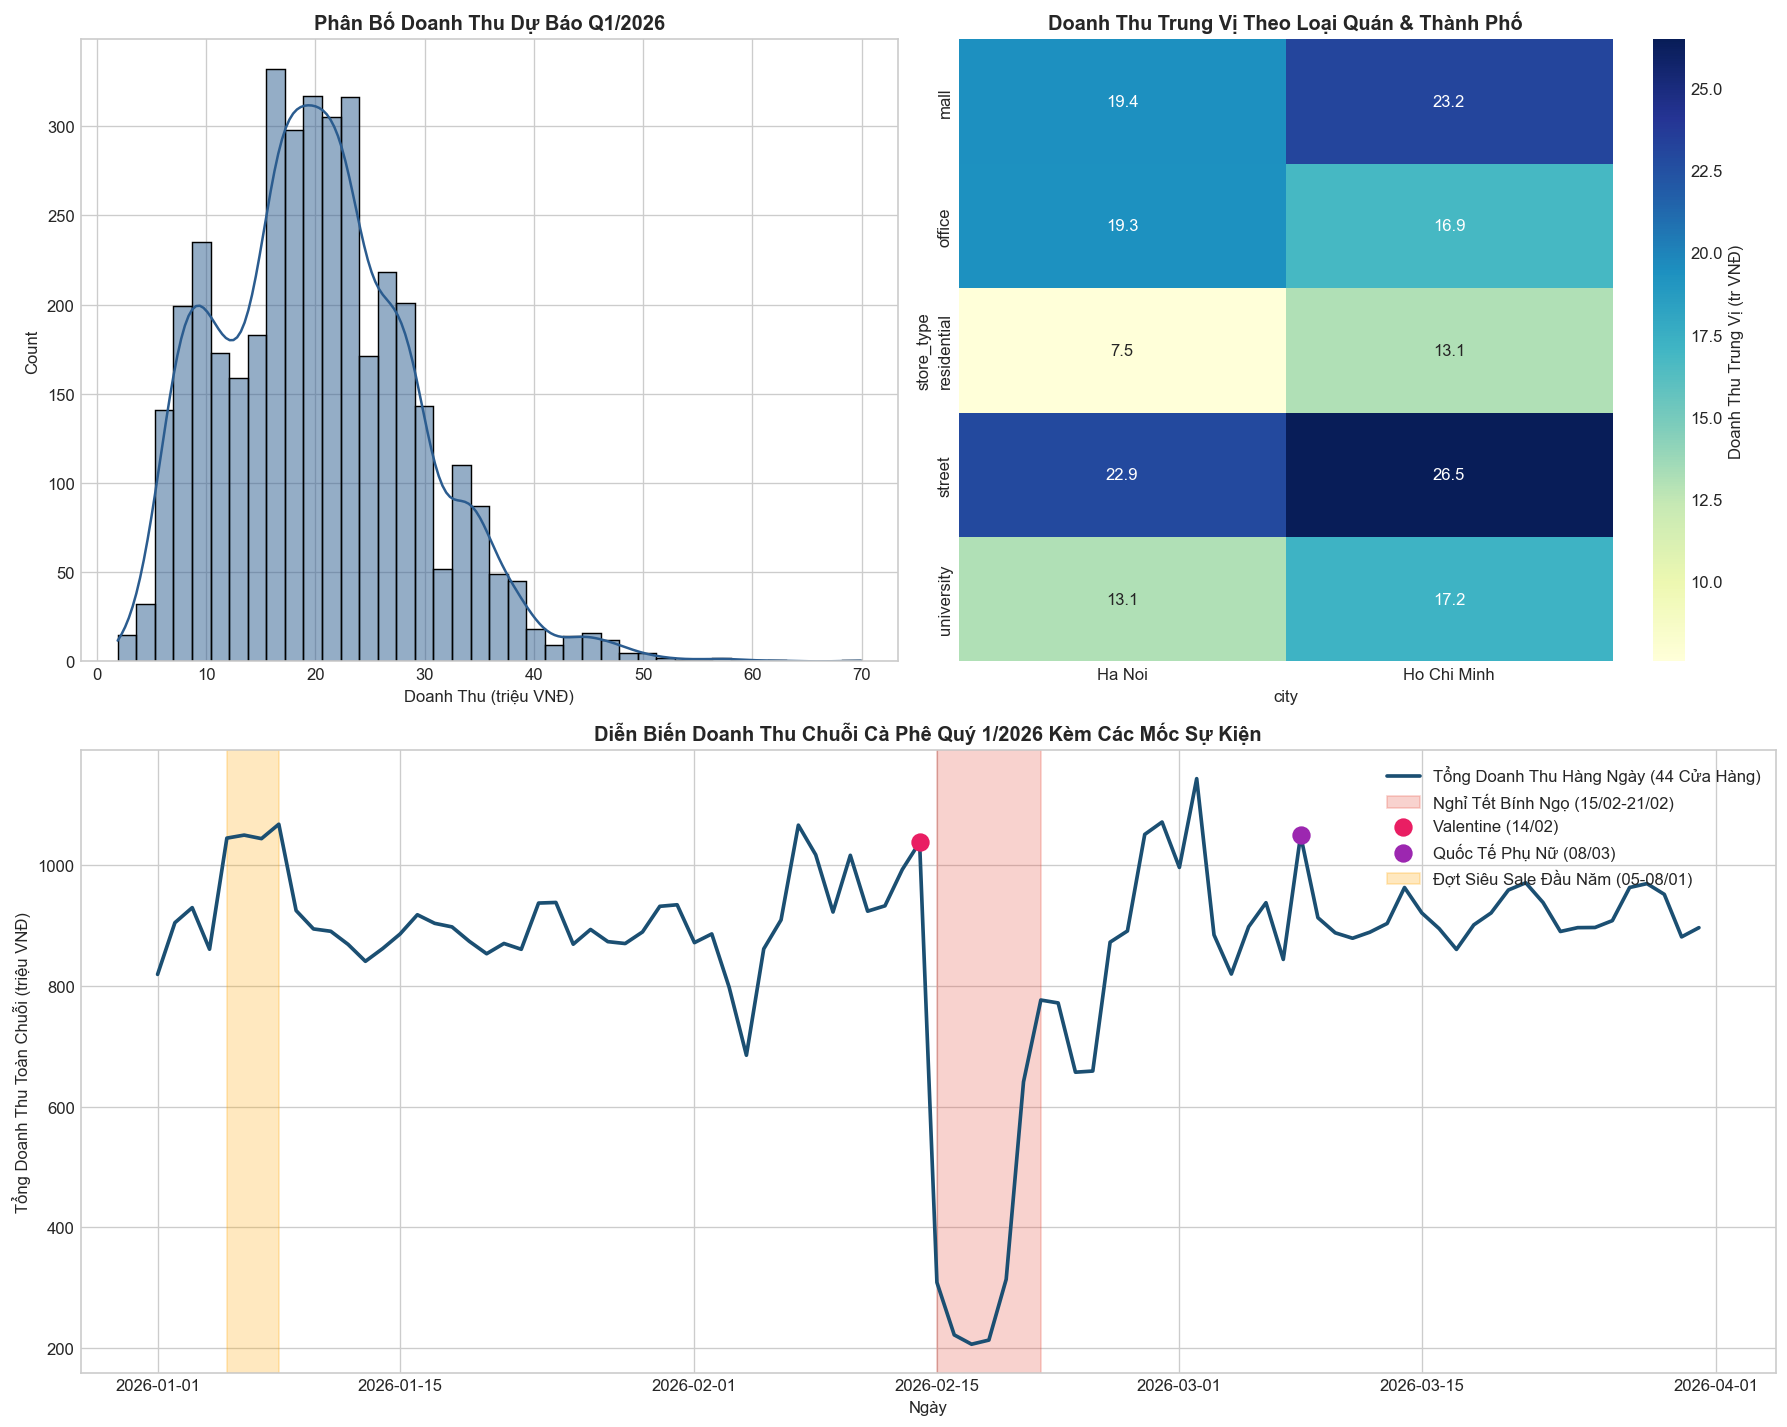

In [2]:
fig = plt.figure(figsize=(15, 12))

# 1. Phân bố tần suất doanh thu
ax1 = plt.subplot(2, 2, 1)
sns.histplot(test_merged["predicted_revenue"], kde=True, ax=ax1, color="#2b5c8f", bins=40)
ax1.set_title("Phân Bố Doanh Thu Dự Báo Q1/2026", fontweight="bold")
ax1.set_xlabel("Doanh Thu (triệu VNĐ)")

# 2. Doanh thu theo loại quán & thành phố
ax2 = plt.subplot(2, 2, 2)
pivot_hm = test_merged.pivot_table(index="store_type", columns="city", values="predicted_revenue", aggfunc="median")
sns.heatmap(pivot_hm, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax2, cbar_kws={'label': 'Doanh Thu Trung Vị (tr VNĐ)'})
ax2.set_title("Doanh Thu Trung Vị Theo Loại Quán & Thành Phố", fontweight="bold")

# 3. Chuỗi thời gian toàn hệ thống
ax3 = plt.subplot(2, 1, 2)
daily_sum = test_merged.groupby("date")["predicted_revenue"].sum()
ax3.plot(daily_sum.index, daily_sum.values, color="#1b4f72", lw=2.2, label="Tổng Doanh Thu Hàng Ngày (44 Cửa Hàng)")
ax3.axvspan(pd.Timestamp("2026-02-15"), pd.Timestamp("2026-02-21"), color="#e74c3c", alpha=0.25, label="Nghỉ Tết Bính Ngọ (15/02-21/02)")
ax3.scatter(pd.Timestamp("2026-02-14"), daily_sum.loc["2026-02-14"], color="#e91e63", s=100, zorder=5, label="Valentine (14/02)")
ax3.scatter(pd.Timestamp("2026-03-08"), daily_sum.loc["2026-03-08"], color="#9c27b0", s=100, zorder=5, label="Quốc Tế Phụ Nữ (08/03)")
ax3.axvspan(pd.Timestamp("2026-01-05"), pd.Timestamp("2026-01-08"), color="orange", alpha=0.25, label="Đợt Siêu Sale Đầu Năm (05-08/01)")

ax3.set_title("Diễn Biến Doanh Thu Chuỗi Cà Phê Quý 1/2026 Kèm Các Mốc Sự Kiện", fontweight="bold")
ax3.set_xlabel("Ngày")
ax3.set_ylabel("Tổng Doanh Thu Toàn Chuỗi (triệu VNĐ)")
ax3.legend(loc="upper right")

plt.tight_layout()
plt.show()

### 3. Xuất File Nộp Bài Chuẩn Kaggle & Kiểm Tra Toàn Vẹn

In [3]:
sub_df = pd.DataFrame({
    "id": test_c["id"].values,
    "revenue": np.round(test_c["predicted_revenue"].values, 4)
})

sub_df.to_csv(SUBMISSION_V3_PATH, index=False)
sub_df.to_csv(SUBMISSION_PATH, index=False)

print("KẾT QUẢ KIỂM ĐỊNH TÍNH TOÀN VẸN SUBMISSION:")
print(f"1. Khớp số lượng dòng (3,869) : {len(sub_df) == len(sample_sub)}")
print(f"2. Khớp đúng tên cột          : {list(sub_df.columns) == ['id', 'revenue']}")
print(f"3. Không chứa giá trị NaN     : {sub_df['revenue'].isna().sum() == 0}")
print(f"4. Không chứa giá trị âm (<0) : {(sub_df['revenue'] < 0).sum() == 0}")
print(f"5. Khớp 100% ID mẫu           : {(sub_df['id'].values == sample_sub['id'].values).all()}")

display(sub_df.head(5))
print(">>> HOÀN THÀNH TOÀN BỘ CHUỖI 5 PHẦN BÁO CÁO TỔNG QUAN!")

KẾT QUẢ KIỂM ĐỊNH TÍNH TOÀN VẸN SUBMISSION:
1. Khớp số lượng dòng (3,869) : True
2. Khớp đúng tên cột          : True
3. Không chứa giá trị NaN     : True
4. Không chứa giá trị âm (<0) : True
5. Khớp 100% ID mẫu           : True


,id,revenue
0,100000,6.5602
1,100001,8.7557
2,100002,21.4346
3,100003,33.1717
4,100004,9.5288


>>> HOÀN THÀNH TOÀN BỘ CHUỖI 5 PHẦN BÁO CÁO TỔNG QUAN!
